### What is a derivative?

A **derivative** is a financial contract whose value depends on (or is *derived from*) an underlying variable, such as an equity price, an index level, an FX rate, or an interest rate.

At a high level, derivatives are used for:

- **Hedging:** transfer risk (e.g., protecting a future sale price).
- **Speculation:** take a view with leverage or convex exposure.
- **Structuring:** create targeted payoff profiles (e.g., digital-like exposures).

In this project, the focus is on **valuation**: given a model and a set of assumptions, compute today's fair value of a contract whose payoff is a function of future uncertainty.

### Notation and conventions

To keep results consistent and reproducible across notebooks and modules:

- $S_0$: spot price at $t=0$
- $K$: strike / delivery price
- $T$: time to maturity in **years**
- $r$: risk-free rate (continuously compounded)
- $q$: dividend yield (continuously compounded)
- $\sigma$: volatility (annualized)

This notebook establishes these conventions; later notebooks focus on instruments, no-arbitrage arguments, and specific pricing models.

### Discounting Factor (continuous compounding)

With continuous compounding, the discount factor for maturity $T$ is:

$$
D(0,T) = e^{-rT}
$$

Present value of a deterministic cashflow $X$ paid at $T$:

$$
PV_0(X) = X e^{-rT}
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dv.discounting import discount_factor

In [2]:
r = 0.05 # risk-free rate
T = 1.0 # time (years)

discf = discount_factor(r, T)

# We proceed to assess discount_factor behavior to corroborate we have no bugs nor incorrect signs or parenthesis
assert discf > 0 # Discount factor must be strictly positive
assert discf <= 1 # With r>=0 and T>=0, discount factor should not exceed 1
assert np.isclose(discount_factor(0.0, 10.0), 1.0) # If r=0, discount factor should be 1
assert np.isclose(discount_factor(0.05, 0.0), 1.0) # If T=0, discount factor should be 1

discf

0.951229424500714

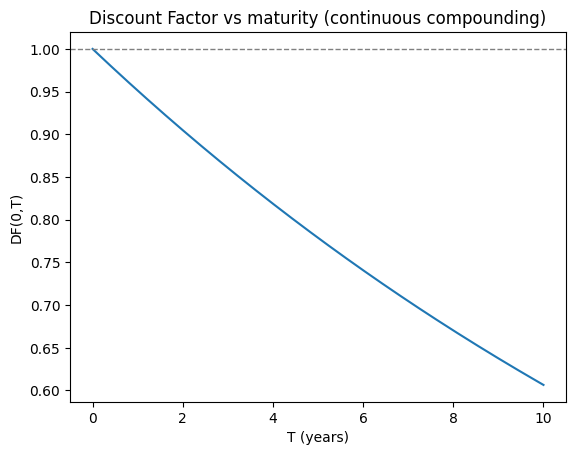

In [ ]:
# Discount Factor as a function of T for a fixed rate (r)
r = 0.05
T_grid = np.linspace(0, 10, 200)
df_T = np.array([discount_factor(r, T) for T in T_grid])

plt.figure()
plt.plot(T_grid, df_T)
plt.title("Discount Factor vs maturity (continuous compounding)")
plt.xlabel("T (years)")
plt.ylabel("DF(0,T)")
plt.axhline(1.0, color="gray", linewidth=1, linestyle="--")
plt.show()

### Notebook Scope

- This notebook deliberately avoids probabilistic pricing and expectations. It's main goal is to establish notation, conventions, and deterministic discounting. Advanced models and pricing measures will be introduced in later chapters.